# Gerçek Telefon Veri Seti (v2) – Keşifçi Veri Analizi (EDA)
**Proje:** TeknoTahmin – Mobil Cihaz Fiyat Segmenti Tahmini
**Veri seti:** `gercek_telefonlar.csv` – 980 gerçek akıllı telefon, gerçek satış fiyatları (Smartprix, Hindistan ₹)
**Kaynak:** [Kaggle – Real World Smartphone's Dataset](https://www.kaggle.com/datasets/abhijitdahatonde/real-world-smartphones-dataset)

Bu notebook, v1'deki (`train.csv`) keşifçi analizin aynısını gerçek telefon verisi için yapıyor:
- Veri setini yüklemek, satır/sütun sayılarına ve veri tiplerine bakmak
- Eksik, tekrarlı ve mantıksal olarak hatalı değerleri bulmak
- Aykırı değerleri (IQR yöntemi) incelemek
- Fiyatı 4 segmente bölüp dağılımına bakmak
- Donanım özelliklerinin fiyata etkisini ve korelasyonları görselleştirmek

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("gercek_telefonlar.csv")
print("Veri seti yüklendi, ilk 5 satır:")
df.head()

Veri seti yüklendi, ilk 5 satır:


,brand_name,model,price,avg_rating,5G_or_not,processor_brand,num_cores,processor_speed,battery_capacity,fast_charging_available,...,internal_memory,screen_size,refresh_rate,num_rear_cameras,os,primary_camera_rear,primary_camera_front,extended_memory_available,resolution_height,resolution_width
0,apple,Apple iPhone 11,38999,7.3,0,bionic,6.0,2.65,3110.0,0,...,64,6.1,60,2,ios,12.0,12.0,0,1792,828
1,apple,Apple iPhone 11 (128GB),46999,7.5,0,bionic,6.0,2.65,3110.0,0,...,128,6.1,60,2,ios,12.0,12.0,0,1792,828
2,apple,Apple iPhone 11 Pro Max,109900,7.7,0,bionic,6.0,2.65,3500.0,1,...,64,6.5,60,3,ios,12.0,12.0,0,2688,1242
3,apple,Apple iPhone 12,51999,7.4,1,bionic,6.0,3.10,NaN,0,...,64,6.1,60,2,ios,12.0,12.0,0,2532,1170
4,apple,Apple iPhone 12 (128GB),55999,7.5,1,bionic,6.0,3.10,NaN,0,...,128,6.1,60,2,ios,12.0,12.0,0,2532,1170


## 1. Satır/Sütun Sayıları, Veri Tipleri ve Özet İstatistikler

In [2]:
print(f"Toplam satır sayısı: {df.shape[0]}")
print(f"Toplam sütun sayısı: {df.shape[1]}")
print(f"Marka sayısı: {df['brand_name'].nunique()}")
print()
df.info()

Toplam satır sayısı: 980
Toplam sütun sayısı: 22
Marka sayısı: 46

<class 'pandas.DataFrame'>
RangeIndex: 980 entries, 0 to 979
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand_name                 980 non-null    str    
 1   model                      980 non-null    str    
 2   price                      980 non-null    int64  
 3   avg_rating                 879 non-null    float64
 4   5G_or_not                  980 non-null    int64  
 5   processor_brand            960 non-null    str    
 6   num_cores                  974 non-null    float64
 7   processor_speed            938 non-null    float64
 8   battery_capacity           969 non-null    float64
 9   fast_charging_available    980 non-null    int64  
 10  fast_charging              769 non-null    float64
 11  ram_capacity               980 non-null    int64  
 12  internal_memory            980 non-null    int64  

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
price,980.0,32520.50,39531.81,3499.00,12999.00,19994.50,35491.50,650000.00
avg_rating,879.0,7.83,0.74,6.00,7.40,8.00,8.40,8.90
5G_or_not,980.0,0.56,0.50,0.00,0.00,1.00,1.00,1.00
num_cores,974.0,7.77,0.84,4.00,8.00,8.00,8.00,8.00
processor_speed,938.0,2.43,0.46,1.20,2.05,2.30,2.84,3.22
battery_capacity,969.0,4817.75,1009.54,1821.00,4500.00,5000.00,5000.00,22000.00
fast_charging_available,980.0,0.85,0.35,0.00,1.00,1.00,1.00,1.00
fast_charging,769.0,46.13,34.28,10.00,18.00,33.00,66.00,240.00
ram_capacity,980.0,6.56,2.74,1.00,4.00,6.00,8.00,18.00
internal_memory,980.0,141.04,107.13,8.00,64.00,128.00,128.00,1024.00


## 2. Eksik Değer (NaN) Kontrolü
v1'deki sentetik veride hiç eksik değer yok. Gerçek veride bazı telefonların bilgileri eksik geliyor.

,Eksik sayısı,Oran (%)
fast_charging,211,21.5
avg_rating,101,10.3
processor_speed,42,4.3
processor_brand,20,2.0
os,14,1.4
battery_capacity,11,1.1
num_cores,6,0.6
primary_camera_front,5,0.5


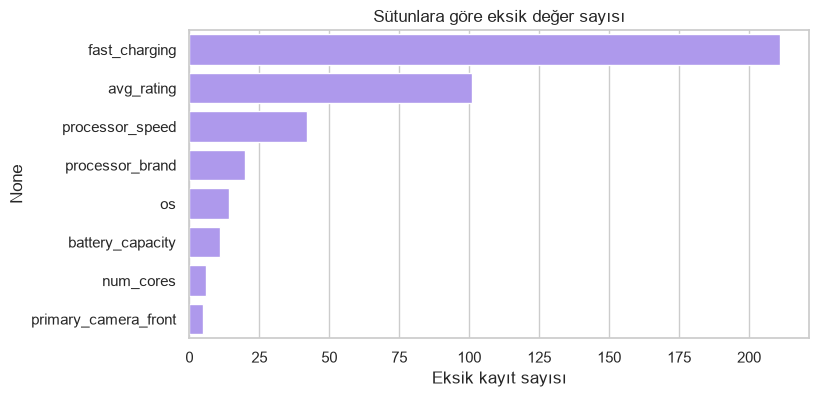

In [4]:
eksik = df.isnull().sum()
eksik = eksik[eksik > 0].sort_values(ascending=False)
eksik_tablo = pd.DataFrame({"Eksik sayısı": eksik, "Oran (%)": (eksik / len(df) * 100).round(1)})
display(eksik_tablo)

plt.figure(figsize=(8, 4))
sns.barplot(x=eksik.values, y=eksik.index, color="#a78bfa")
plt.title("Sütunlara göre eksik değer sayısı")
plt.xlabel("Eksik kayıt sayısı")
plt.show()

In [5]:
# Hızlı şarj gücü (W) eksik olanlar: telefonda hızlı şarj yok mu, yoksa bilgi mi eksik?
nan_sarj = df["fast_charging"].isna()
print("Hızlı şarj gücü eksik:", nan_sarj.sum())
print("  - bunlardan hızlı şarjı OLMAYAN (normal, 0 W kabul ediliyor):", (nan_sarj & (df["fast_charging_available"] == 0)).sum())
print("  - hızlı şarjı OLDUĞU hâlde watt bilgisi eksik:", (nan_sarj & (df["fast_charging_available"] == 1)).sum())

Hızlı şarj gücü eksik: 211
  - bunlardan hızlı şarjı OLMAYAN (normal, 0 W kabul ediliyor): 143
  - hızlı şarjı OLDUĞU hâlde watt bilgisi eksik: 68


## 3. Tekrarlayan Kayıt (Duplicate) Kontrolü

In [6]:
print("Birebir tekrar eden satır:", df.duplicated().sum())
print("Aynı model adıyla tekrar eden kayıt:", df["model"].duplicated().sum())
print("Not: Aynı telefonun farklı RAM/depolama varyantları ayrı satırlar, model adları da farklı yazılıyor (ör. '(8GB RAM + 256GB)').")

Birebir tekrar eden satır: 0
Aynı model adıyla tekrar eden kayıt: 0
Not: Aynı telefonun farklı RAM/depolama varyantları ayrı satırlar, model adları da farklı yazılıyor (ör. '(8GB RAM + 256GB)').


## 4. Mantıksal Hata ve Anormal Değer Tespiti
Teknik olarak hata vermeyen ama alan bilgisiyle bakınca şüpheli görünen değerler kontrol ediliyor.

In [7]:
kontroller = {
    "Hızlı şarj yok ama watt bilgisi var": ((df["fast_charging_available"] == 0) & df["fast_charging"].notna()).sum(),
    "RAM, depolamadan büyük": (df["ram_capacity"] > df["internal_memory"]).sum(),
    "Ön kamera 0 MP": (df["primary_camera_front"] == 0).sum(),
    "Ekran genişliği (piksel) yüksekliğinden büyük": (df["resolution_width"] > df["resolution_height"]).sum(),
    "Ekran 5 inçten küçük": (df["screen_size"] < 5).sum(),
    "Ekran 7 inçten büyük (katlanabilir/tablet)": (df["screen_size"] > 7).sum(),
    "Batarya 9000 mAh üzeri": (df["battery_capacity"] > 9000).sum(),
    "Fiyat 165.000 ₹ üzeri (lüks)": (df["price"] > 165000).sum(),
}
pd.DataFrame({"Kayıt sayısı": kontroller})

,Kayıt sayısı
Hızlı şarj yok ama watt bilgisi var,0
"RAM, depolamadan büyük",0
Ön kamera 0 MP,1
Ekran genişliği (piksel) yüksekliğinden büyük,39
Ekran 5 inçten küçük,8
Ekran 7 inçten büyük (katlanabilir/tablet),18
Batarya 9000 mAh üzeri,3
Fiyat 165.000 ₹ üzeri (lüks),10


**Dikkat:** Telefon ekranında piksel yüksekliği her zaman genişlikten büyük olmalı. Genişliği büyük görünen telefonlarda
iki değer ters girilmiş (ör. 2400 × 1080 yerine 1080 × 2400). Bu bir veri giriş hatası:

In [8]:
ters = df[df["resolution_width"] > df["resolution_height"]]
print(f"Çözünürlüğü ters girilmiş telefon: {len(ters)}")
print("Markalara göre:", ters["brand_name"].value_counts().head(5).to_dict())
ters[["brand_name", "model", "resolution_width", "resolution_height"]].head(8)

Çözünürlüğü ters girilmiş telefon: 39
Markalara göre: {'itel': 9, 'oppo': 5, 'xiaomi': 5, 'infinix': 4, 'samsung': 4}


,brand_name,model,resolution_width,resolution_height
111,infinix,Infinix Hot 12 Play,1640,720
121,infinix,Infinix Note 12,2400,1080
122,infinix,Infinix Note 12 (6GB RAM + 128GB),2400,1080
127,infinix,Infinix Note 12 Turbo,2400,1080
170,itel,Itel A23 Pro,854,480
171,itel,itel A23s,854,480
172,itel,Itel A24 Pro,854,480
174,itel,itel P36,1600,720


In [9]:
print("En pahalı 10 telefon:")
display(df.nlargest(10, "price")[["brand_name", "model", "price"]])
print("Bataryası en büyük 3 telefon:")
display(df.nlargest(3, "battery_capacity")[["brand_name", "model", "battery_capacity"]])

En pahalı 10 telefon:


,brand_name,model,price
732,vertu,Vertu Signature Touch,650000
909,xiaomi,Xiaomi Redmi K20 Pro Signature Edition,480000
94,huawei,Huawei Mate 50 RS Porsche Design,239999
91,huawei,Huawei Mate 30 RS Porsche Design,214990
873,xiaomi,Xiaomi Mi Mix Alpha,199990
32,apple,Apple iPhone 14 Pro Max (1TB),182999
19,apple,Apple iPhone 13 Pro Max (1TB),179900
29,apple,Apple iPhone 14 Pro (1TB),172999
34,apple,Apple iPhone 14 Pro Max (512GB),169900
95,huawei,Huawei Mate X,169000


Bataryası en büyük 3 telefon:


,brand_name,model,battery_capacity
58,doogee,Doogee V Max,22000.0
409,oukitel,Oukitel WP19,21000.0
410,oukitel,Oukitel WP21,9800.0


## 5. Aykırı Değer (Outlier) Tespiti – IQR Yöntemi
Her sayısal sütun için alt sınır $Q_1 - 1.5 \times IQR$, üst sınır $Q_3 + 1.5 \times IQR$ alınıyor.

In [10]:
satirlar = []
for s in ["price", "battery_capacity", "fast_charging", "ram_capacity", "internal_memory", "screen_size",
          "refresh_rate", "primary_camera_rear", "primary_camera_front", "processor_speed", "resolution_height"]:
    q1, q3 = df[s].quantile([.25, .75])
    iqr = q3 - q1
    alt, ust = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[s] < alt) | (df[s] > ust)).sum()
    satirlar.append([s, round(alt, 2), round(ust, 2), n, df[s].min(), df[s].max()])
pd.DataFrame(satirlar, columns=["Sütun", "Alt sınır", "Üst sınır", "Aykırı sayısı", "Min", "Maks"])

,Sütun,Alt sınır,Üst sınır,Aykırı sayısı,Min,Maks
0,price,-20739.75,69230.25,107,3499.00,650000.00
1,battery_capacity,3750.00,5750.00,129,1821.00,22000.00
2,fast_charging,-54.00,138.00,13,10.00,240.00
3,ram_capacity,-2.00,14.00,11,1.00,18.00
4,internal_memory,-32.00,224.00,184,8.00,1024.00
5,screen_size,6.25,6.92,113,3.54,8.03
6,refresh_rate,-30.00,210.00,1,60.00,240.00
7,primary_camera_rear,-36.00,124.00,18,2.00,200.00
8,primary_camera_front,-4.00,28.00,193,0.00,60.00
9,processor_speed,0.86,4.03,0,1.20,3.22


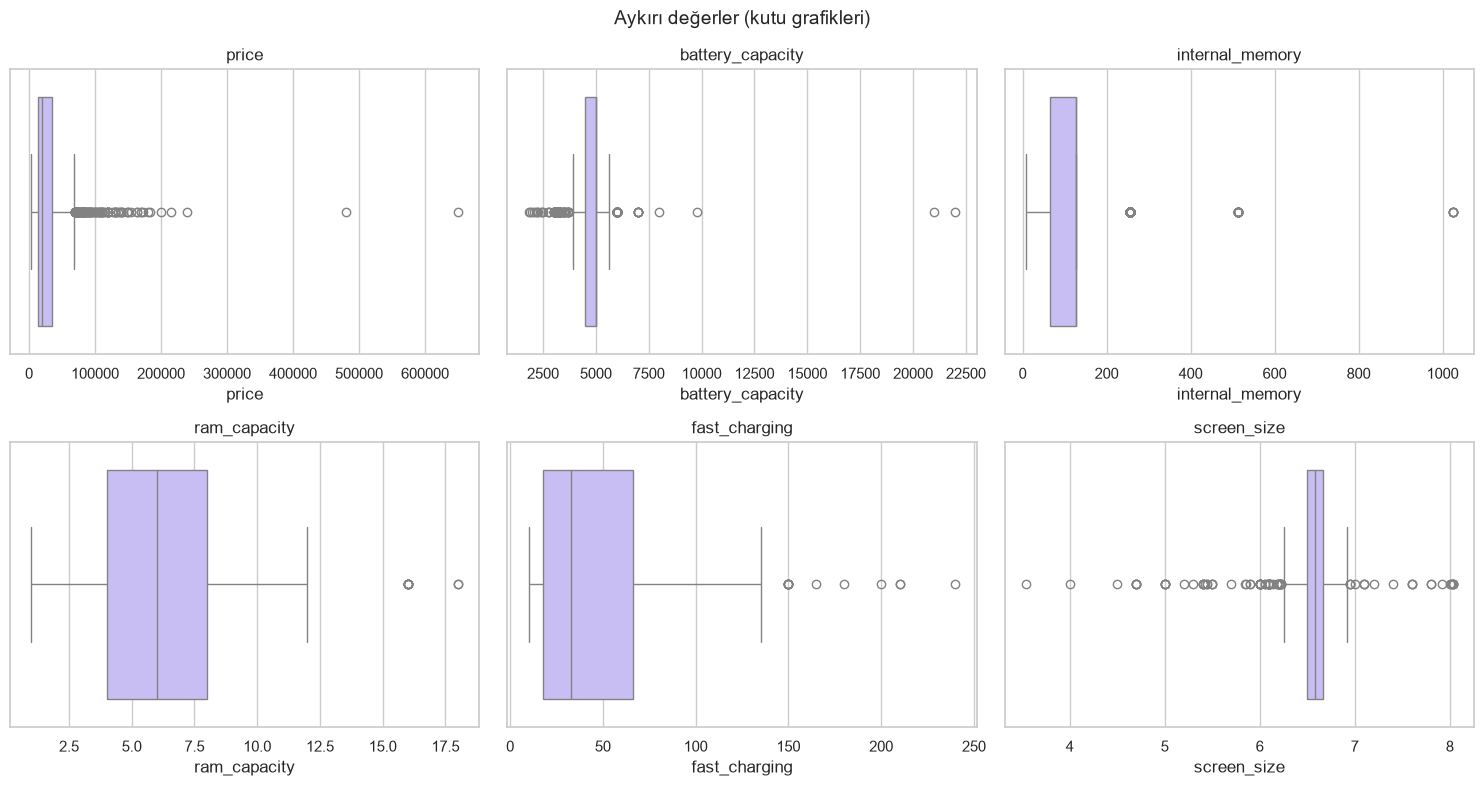

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, s in zip(axes.ravel(), ["price", "battery_capacity", "internal_memory", "ram_capacity", "fast_charging", "screen_size"]):
    sns.boxplot(x=df[s], ax=ax, color="#c4b5fd")
    ax.set_title(s)
plt.suptitle("Aykırı değerler (kutu grafikleri)", fontsize=14)
plt.tight_layout()
plt.show()

## 6. Temizlik Adımları (analizde uygulananlar)
- Fiyat dağılımını bozan **en pahalı %1'lik 10 lüks telefon** (ör. Vertu, Porsche Design) çıkarılıyor.
- Ekran çözünürlüğü ters girilmiş **39 telefonda** genişlik ve yükseklik yer değiştiriliyor.
- Hızlı şarj gücü eksik olanlar **0 W** kabul ediliyor.
- İşlemci hızı, çekirdek sayısı, batarya ve ön kamerada eksik değerler **medyanla** dolduruluyor.
- Fiyat, **4 eşit gruba (çeyrek)** bölünerek hedef değişken (`price_range`) oluşturuluyor.

In [12]:
temiz = df[df["price"] <= df["price"].quantile(0.99)].copy()
temiz["fast_charging"] = temiz["fast_charging"].fillna(0)
ters = temiz["resolution_width"] > temiz["resolution_height"]
temiz.loc[ters, ["resolution_width", "resolution_height"]] = temiz.loc[ters, ["resolution_height", "resolution_width"]].values
print(f"Çözünürlüğü ters girilmiş {ters.sum()} telefon düzeltiliyor.")
for s in ["processor_speed", "num_cores", "battery_capacity", "primary_camera_front"]:
    temiz[s] = temiz[s].fillna(temiz[s].median())
temiz["price_range"], sinirlar = pd.qcut(temiz["price"], 4, labels=False, retbins=True)
print(f"Temizlikten sonra kalan telefon: {len(temiz)} (çıkarılan: {len(df) - len(temiz)})")
print("Segment sınırları (₹):", [int(x) for x in sinirlar])
print("Modelde kullanılan sütunlarda kalan eksik değer:",
      temiz[["processor_speed", "num_cores", "battery_capacity", "primary_camera_front", "fast_charging"]].isnull().sum().sum())

Çözünürlüğü ters girilmiş 39 telefon düzeltiliyor.
Temizlikten sonra kalan telefon: 970 (çıkarılan: 10)
Segment sınırları (₹): [3499, 12999, 19990, 34999, 163980]
Modelde kullanılan sütunlarda kalan eksik değer: 0


## 7. Fiyat ve Fiyat Segmentlerinin Dağılımı

,Fiyat segmenti,Telefon sayısı,Oran (%),Fiyat aralığı (₹)
0,0 (Düşük),249,25.7,"3,499 – 12,999"
1,1 (Orta),241,24.8,"12,999 – 19,990"
2,2 (Yüksek),243,25.1,"19,990 – 34,999"
3,3 (Çok yüksek),237,24.4,"34,999 – 163,980"


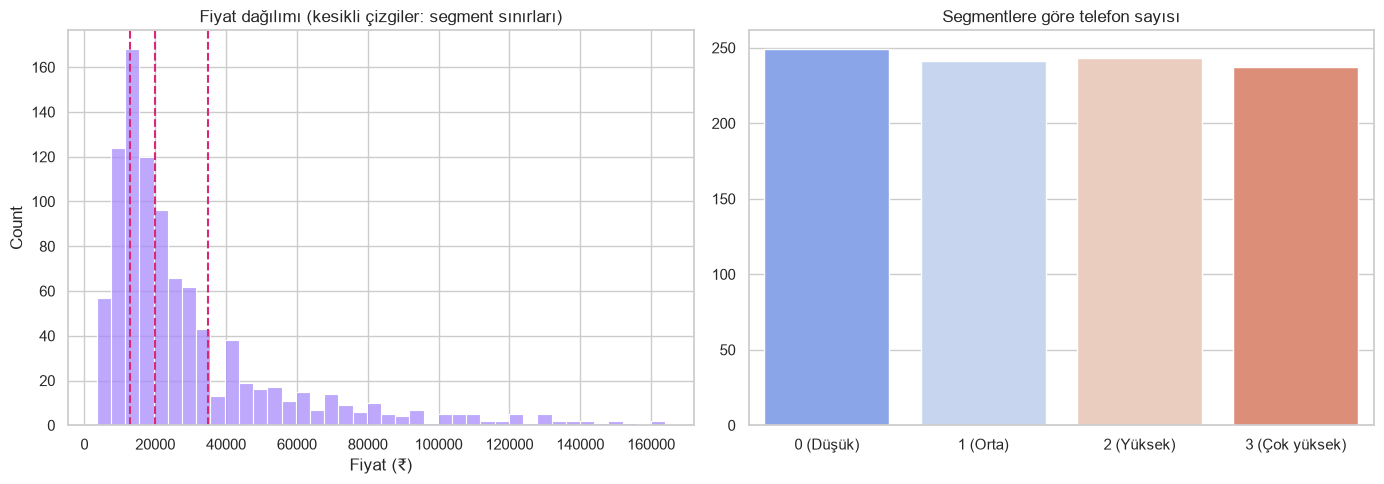

In [13]:
adlar = ["0 (Düşük)", "1 (Orta)", "2 (Yüksek)", "3 (Çok yüksek)"]
sayilar = temiz["price_range"].value_counts().sort_index()
display(pd.DataFrame({"Fiyat segmenti": adlar, "Telefon sayısı": sayilar.values,
                      "Oran (%)": (sayilar.values / len(temiz) * 100).round(1),
                      "Fiyat aralığı (₹)": [f"{int(sinirlar[i]):,} – {int(sinirlar[i + 1]):,}" for i in range(4)]}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(temiz["price"], bins=40, ax=axes[0], color="#a78bfa")
for x in sinirlar[1:-1]:
    axes[0].axvline(x, color="#db2777", linestyle="--")
axes[0].set_title("Fiyat dağılımı (kesikli çizgiler: segment sınırları)")
axes[0].set_xlabel("Fiyat (₹)")
sns.barplot(x=adlar, y=sayilar.values, ax=axes[1], hue=adlar, palette="coolwarm", legend=False)
axes[1].set_title("Segmentlere göre telefon sayısı")
plt.tight_layout()
plt.show()

Fiyat sağa çarpık: telefonların çoğu ucuz ve orta fiyatlı, az sayıda pahalı telefon kuyruğu uzatıyor. Çeyreklere bölündüğü için 4 segment dengeli (her birinde yaklaşık 240 telefon).

## 8. Markalara Göre Dağılım

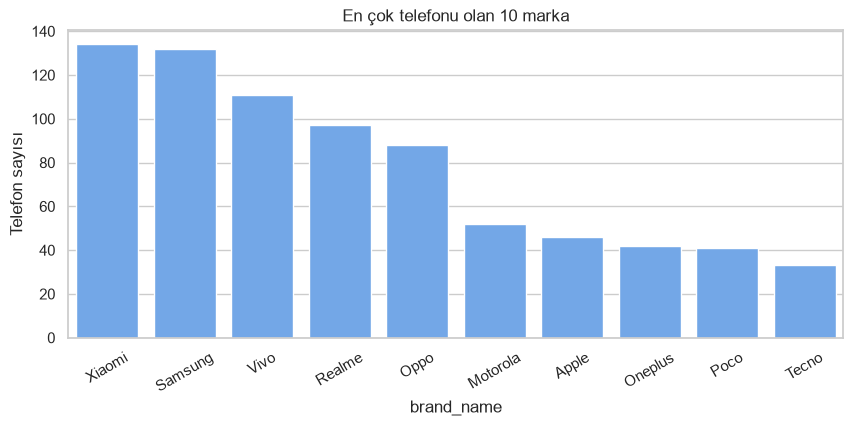

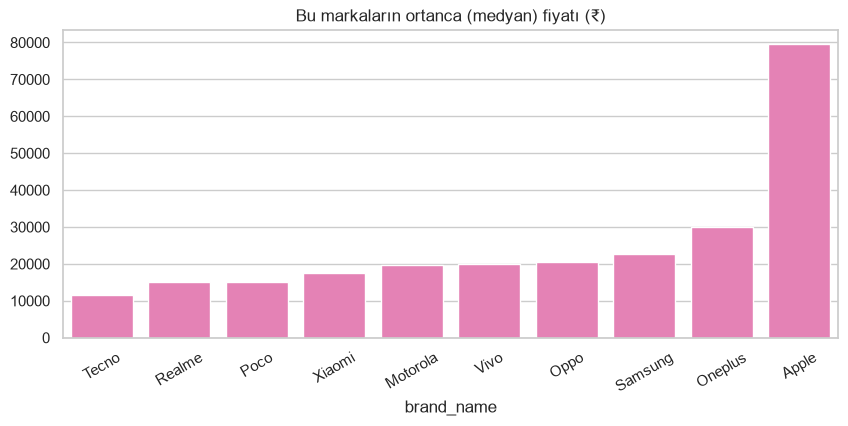

In [14]:
ilk10 = df["brand_name"].value_counts().head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=ilk10.index.str.title(), y=ilk10.values, color="#60a5fa")
plt.title("En çok telefonu olan 10 marka")
plt.ylabel("Telefon sayısı")
plt.xticks(rotation=30)
plt.show()

marka_fiyat = temiz.groupby("brand_name")["price"].median().loc[ilk10.index].sort_values()
plt.figure(figsize=(10, 4))
sns.barplot(x=marka_fiyat.index.str.title(), y=marka_fiyat.values, color="#f472b6")
plt.title("Bu markaların ortanca (medyan) fiyatı (₹)")
plt.xticks(rotation=30)
plt.show()

## 9. Donanım Özelliklerinin Fiyata Etkisi
Fiyatla ilişkisi en güçlü özelliklerin segmentlere göre dağılımı: işlemci hızı, depolama, RAM, hızlı şarj ve ekran çözünürlüğü.

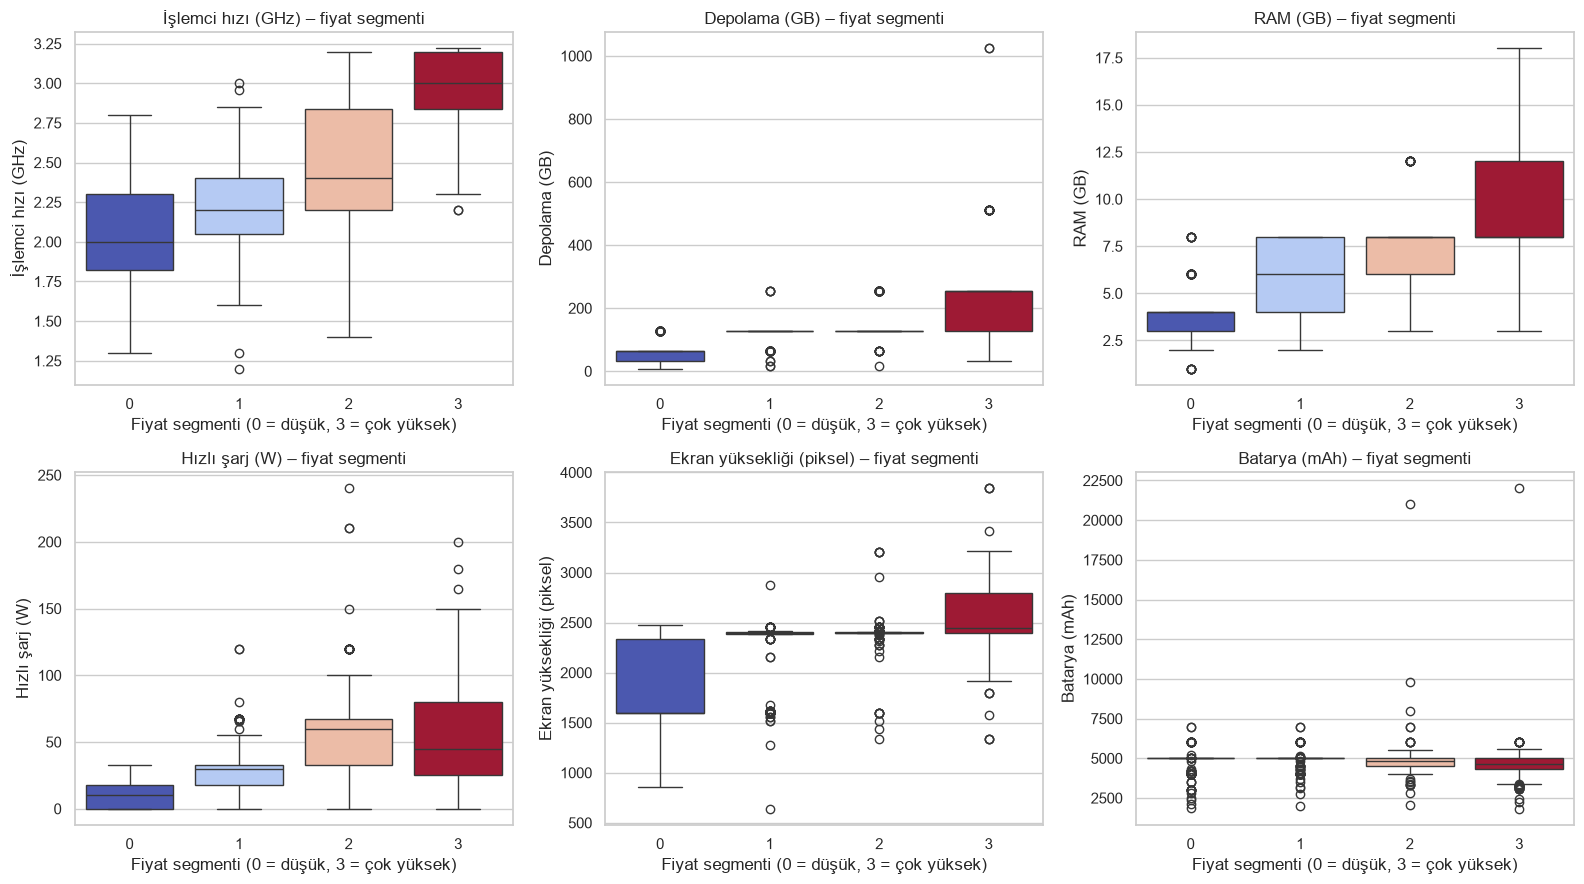

In [15]:
ozellikler = [("processor_speed", "İşlemci hızı (GHz)"), ("internal_memory", "Depolama (GB)"),
              ("ram_capacity", "RAM (GB)"), ("fast_charging", "Hızlı şarj (W)"),
              ("resolution_height", "Ekran yüksekliği (piksel)"), ("battery_capacity", "Batarya (mAh)")]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (s, ad) in zip(axes.ravel(), ozellikler):
    sns.boxplot(x="price_range", y=s, data=temiz, ax=ax, hue="price_range", palette="coolwarm", legend=False)
    ax.set_title(f"{ad} – fiyat segmenti")
    ax.set_xlabel("Fiyat segmenti (0 = düşük, 3 = çok yüksek)")
    ax.set_ylabel(ad)
plt.tight_layout()
plt.show()

İşlemci hızı, depolama ve RAM segment yükseldikçe açıkça artıyor. Batarya ise neredeyse hiç değişmiyor: ucuz telefonlarda da 5000 mAh yaygın.

## 10. Korelasyon Matrisi (Heatmap)

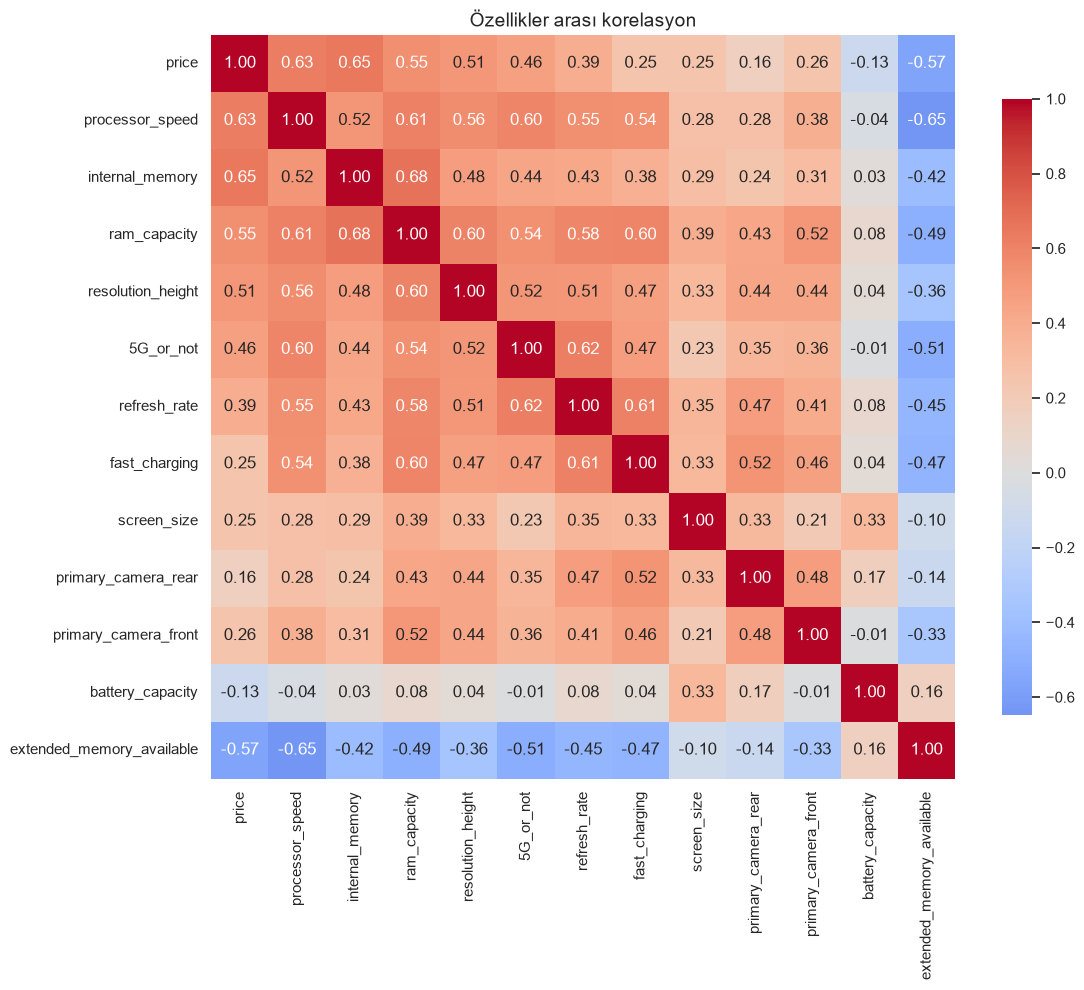

Fiyatla korelasyon (büyükten küçüğe):


,Fiyatla korelasyon
internal_memory,0.652
processor_speed,0.630
ram_capacity,0.550
resolution_height,0.506
5G_or_not,0.460
refresh_rate,0.390
primary_camera_front,0.259
fast_charging,0.249
screen_size,0.248
primary_camera_rear,0.160


In [16]:
secilen = ["price", "processor_speed", "internal_memory", "ram_capacity", "resolution_height", "5G_or_not",
           "refresh_rate", "fast_charging", "screen_size", "primary_camera_rear", "primary_camera_front",
           "battery_capacity", "extended_memory_available"]
plt.figure(figsize=(12, 10))
sns.heatmap(temiz[secilen].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Özellikler arası korelasyon", fontsize=14)
plt.show()

print("Fiyatla korelasyon (büyükten küçüğe):")
display(temiz[secilen].corr()["price"].drop("price").sort_values(ascending=False).round(3).to_frame("Fiyatla korelasyon"))

## 11. Sonuç ve v1 ile Karşılaştırma

| Konu | v1 (sentetik, `train.csv`) | v2 (gerçek telefonlar) |
| :--- | :--- | :--- |
| Satır sayısı | 2000 | 980 (temizlikten sonra 970) |
| Eksik değer | Yok | Var: hızlı şarj gücü, kullanıcı puanı, işlemci hızı vb. |
| Tekrarlı kayıt | Yok | Yok |
| Mantıksal hata | `px_height = 0`, `sc_w = 0` | 39 telefonda çözünürlük ters girilmiş (genişlik ↔ yükseklik); ayrıca gerçek uç değerler (22.000 mAh batarya, 650.000 ₹ Vertu) |
| Segmentler | Hazır geliyor, her birinde 500 | Fiyattan çeyreklerle oluşturuluyor, her birinde ~240 |
| En belirleyici özellik | RAM (korelasyon 0,92) | İşlemci hızı, depolama, RAM birlikte (0,5–0,7) |

**Öne çıkanlar:**
- Gerçek veride eksik değerler var ama çoğu anlamlı: hızlı şarj gücü eksik olan 211 telefonun 143'ünde hızlı şarj zaten yok.
- 39 telefonda ekran çözünürlüğünün genişlik ve yüksekliği yer değiştirmiş. Analizde bu telefonlarda iki değerin yeri değiştiriliyor.
- Aykırı değerlerin çoğu gerçek telefonlar (katlanabilir ekranlar, 1 TB depolamalı amiral gemileri). Sadece fiyat dağılımını bozan en pahalı %1 çıkarılıyor.
- v1'de fiyatı neredeyse tek başına RAM belirliyor. v2'de birden fazla özellik birlikte etkili, bu da gerçek piyasaya daha yakın bir tablo veriyor.